# The authors' trained U-Net, running in PyTorch

This notebook runs the U-Net that Ronneberger et al. released after the **ISBI 2015 cell tracking challenge**, using their trained weights from `u-net-release/phseg_v5.caffemodel`. Nothing is trained here: it loads a finished network and uses it to segment phase-contrast microscope images of cells (the PhC-C2DH-U373 dataset).

To train a U-Net yourself, see `train_isbi2012.ipynb`.

**How to run it:** choose the kernel **Python (unet)** and use **Run All**. It takes under a minute.

The code it calls is in `pyunet/`:
- `caffemodel.py` reads the weights out of the Caffe file, using only numpy. Caffe isn't needed.
- `model.py` is the network, built layer for layer from `phseg_v5-train.prototxt`.
- `tiling.py` predicts whole images with the overlap-tile method from `mycaffe_tiled_forward5.m`.

`python check_port.py` runs automatic checks that the port is correct.

## 1. Imports

- `torch` is PyTorch, the deep-learning library.
- `numpy` handles arrays, `matplotlib` makes plots, `tifffile` reads the microscope `.tif` files, and `scipy.ndimage` finds connected regions (separate cells) in a mask.
- `pyunet` is our own package.

`device` is `"cuda"` when PyTorch can see your NVIDIA GPU. All the network maths then runs there.

In [1]:
%load_ext autoreload
%autoreload 2

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile
import torch
from scipy import ndimage

import pyunet

RELEASE = Path("u-net-release")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__, device)

2.6.0+cu124 cuda


## 2. Load the released weights

`load_pretrained` does three things:
1. builds an empty network (`UNetPhseg`) with the same layers as the authors' Caffe model
2. reads the 23 weight layers from the `.caffemodel` file and copies them in, checking every shape matches
3. moves the network to the GPU and switches it to **eval mode**, which turns off dropout. Dropout is only used while training.

The parameter count should be 31,100,354. The paper's figure would give 31,030,658; the difference comes from the released net's last up-convolution keeping 128 channels instead of 64.

In [2]:
model = pyunet.load_pretrained(RELEASE / "phseg_v5.caffemodel", device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

31,100,354 parameters


## 3. Shape trace

To see the U shape in numbers, we push a blank 572×572 image through the network and record the output size of each block. A *forward hook* is a small function PyTorch calls every time a layer runs; here it just notes the shape.

Read the list top to bottom:
- **down0 to down4**, the contracting path: the image shrinks (568 → 280 → 136 → 64 → 28) while the number of channels doubles (64 → 1024). Each block loses 4 pixels to its two unpadded 3×3 convolutions, then max pooling halves the size.
- **up3 to up0**, the expanding path: the size doubles at each up-convolution, and the channels shrink back.
- **score**, a 1×1 convolution, gives 2 numbers per pixel: one score for background and one for cell.

The output is 388×388 for a 572×572 input, exactly as in the paper's Fig. 1. The 92-pixel border lost on each side is the context each output pixel needs. Compare with section 4 of `unet_notes.md`.

In [3]:
shapes = []
hooks = [
    m.register_forward_hook(lambda mod, inp, out, name=name: shapes.append((name, tuple(out.shape[1:]))))
    for name, m in model.named_children()
    if name != "pool"
]
with torch.inference_mode():
    model(torch.zeros(1, 1, 572, 572, device=device))
for h in hooks:
    h.remove()

print("input  572x572 x 1")
for name, (c, h, w) in shapes:
    print(f"{name:6s} {h}x{w} x {c}")

input  572x572 x 1
down0  568x568 x 64
down1  280x280 x 128
down2  136x136 x 256
down3  64x64 x 512
down4  28x28 x 1024
up3    52x52 x 512
up2    100x100 x 256
up1    196x196 x 128
up0    388x388 x 64
score  388x388 x 2


## 4. Segment the sample frames

The release includes two frames of glioblastoma-astrocytoma cells, filmed with phase-contrast microscopy. Each frame is 520×696 pixels, 8-bit.

`pyunet.predict` uses the same settings as the authors' `segmentAndTrack.sh`:
- **Overlap-tile** (paper Fig. 2, notes §5). The image is mirrored outward by 92 pixels, then cut into 2 tiles stacked vertically. Each tile's input is 444×892 and its output is 260×708, so the outputs fit together to cover the whole image.
- **Flip averaging.** Each tile is predicted four times (as is, flipped left-right, flipped up-down, and both), the predictions are flipped back, and the scores averaged. That smooths out small mistakes.

Each frame takes well under a second on the GPU.

In [4]:
frames = sorted((RELEASE / "PhC-C2DH-U373" / "01").glob("t*.tif"))
images = [tifffile.imread(f) for f in frames]
print([f.name for f in frames], images[0].shape, images[0].dtype)
print("tile input/output sizes:", pyunet.tile_geometry(images[0].shape, (2, 1)))

results = []
for f, img in zip(frames, images):
    t = time.time()
    results.append(pyunet.predict(model, img, n_tiles=(2, 1), flip_average=True))
    print(f"{f.name}: {time.time() - t:.2f}s")

['t000.tif', 't001.tif'] (520, 696) uint8
tile input/output sizes: ((444, 892), (260, 708))


t000.tif: 0.33s


t001.tif: 0.30s


## 5. Look at the result

`predict` returns raw scores of shape `(2, height, width)`: two numbers per pixel. Two steps turn them into something useful:
- **softmax** turns the two scores into probabilities that add up to 1. Channel 1 is P(cell).
- **argmax** picks the class with the higher score: 1 means cell, 0 means background. That gives the mask, outlined in green.

The probability map is close to 0 or 1 almost everywhere: the network is confident. Uncertain values only appear in a thin band at cell edges. Note also that the small bright debris particles are correctly ignored.

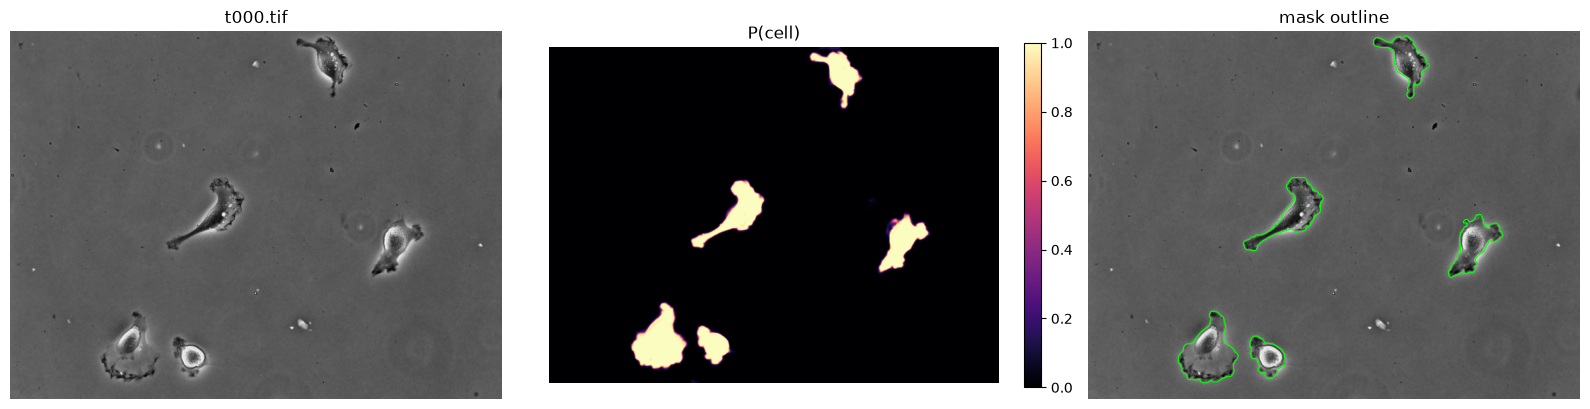

In [5]:
img, scores = images[0], results[0]
prob = pyunet.softmax(scores)[1]  # class 1 = cell
mask = scores.argmax(0) == 1

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].imshow(img, cmap="gray")
ax[0].set_title(frames[0].name)
im = ax[1].imshow(prob, cmap="magma", vmin=0, vmax=1)
ax[1].set_title("P(cell)")
fig.colorbar(im, ax=ax[1], fraction=0.035)
ax[2].imshow(img, cmap="gray")
ax[2].contour(mask, levels=[0.5], colors="lime", linewidths=0.8)
ax[2].set_title("mask outline")
for a in ax:
    a.axis("off")
plt.tight_layout()

## 6. From a mask to individual cells

The mask says *which pixels* are cell, but not *which cell* each pixel belongs to. `ndimage.label` finds connected regions and gives each one its own number. We use 8-connectivity, meaning diagonal neighbours count as touching, which matches MATLAB's `bwconncomp` in `trackCells2.m`.

Like the authors' tracker, we then drop regions of 500 pixels or fewer (`minSegmAreaPx`) as noise, and renumber what's left. Each cell gets its own colour.

Each frame is numbered on its own here, so a cell's colour in one frame isn't guaranteed to match the next. Here they happen to match because the cells barely move. The authors' tracker (`trackCells2.m`) adds that missing step: it matches each cell to the one it overlaps most in the previous frame.

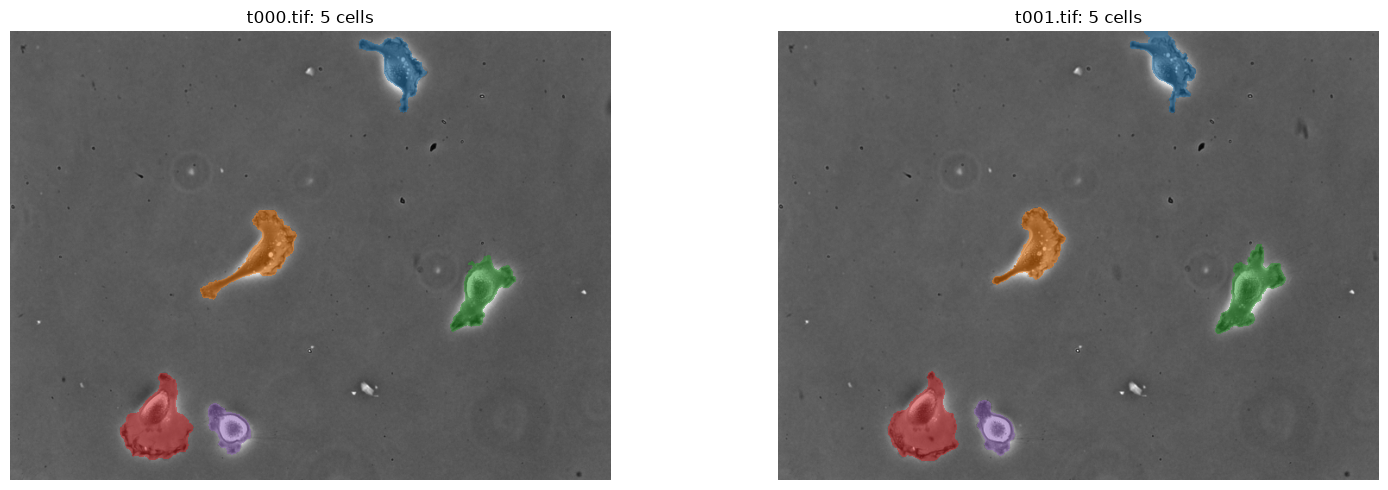

In [6]:
def label_cells(mask, min_area=500):
    labels, n = ndimage.label(mask, structure=np.ones((3, 3)))
    areas = ndimage.sum(mask, labels, index=np.arange(1, n + 1))
    keep = np.concatenate([[False], areas > min_area])
    return ndimage.label(keep[labels], structure=np.ones((3, 3)))


fig, ax = plt.subplots(1, len(results), figsize=(8 * len(results), 5))
for a, f, img, scores in zip(np.atleast_1d(ax), frames, images, results):
    labels, n = label_cells(scores.argmax(0) == 1)
    a.imshow(img, cmap="gray")
    a.imshow(np.ma.masked_equal(labels, 0), cmap="tab10", vmin=1, vmax=10, alpha=0.5, interpolation="nearest")
    a.set_title(f"{f.name}: {n} cells")
    a.axis("off")
plt.tight_layout()

## 7. How much do the inference tricks matter?

Here we re-segment the first frame with different settings and count how many pixels change label compared with the full method (2 tiles plus flip averaging).

The answer is very few: well under 0.1% of pixels. Two things cause the small differences:
- **Flip averaging** smooths borderline pixels at cell edges.
- **Tiling.** Tiles start at offsets that aren't multiples of 16, so the 2×2 pooling grid lines up slightly differently inside each tile.

The tricks matter more for harder images, or for networks trained on less data.

In [7]:
reference = results[0].argmax(0)
for n_tiles, flips in [((2, 1), False), ((1, 1), True), ((1, 1), False), ((3, 3), True)]:
    labels = pyunet.predict(model, images[0], n_tiles=n_tiles, flip_average=flips).argmax(0)
    print(f"n_tiles={n_tiles}, flip_average={flips}: {(labels != reference).sum()} pixels differ "
          f"({(labels != reference).mean():.3%})")

n_tiles=(2, 1), flip_average=False: 242 pixels differ (0.067%)


n_tiles=(1, 1), flip_average=True: 35 pixels differ (0.010%)
n_tiles=(1, 1), flip_average=False: 249 pixels differ (0.069%)


n_tiles=(3, 3), flip_average=True: 58 pixels differ (0.016%)
